In [1]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
file = np.load('DataTrain.npy')
device = torch.device("cuda" if torch.cuda.is_available() else "cpu") #moving all the weights to the GPU
data = torch.tensor(file, dtype=torch.float32)
features = data[:,:-1] #getting just the features
fraud = data[:, -1].float() #just the fraud
dataset = torch.utils.data.TensorDataset(features, fraud) #creating a dataset with separate features and fraud
loader = torch.utils.data.DataLoader(dataset, batch_size=512, shuffle=True,num_workers=4, pin_memory=True)

In [3]:
class Model(nn.Module):
  def __init__(self, input_size, layerSize = [128, 64, 32, 16]):
    super(Model, self).__init__()
    layers = []
    c = input_size
    for s in layerSize:
        layers.append(nn.Linear(c, s))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.2))
        c = s
    layers.append(nn.Linear(c, 1))
    self.model = nn.Sequential(*layers)

  def forward(self, x):
    return self.model(x)

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = Model(features.shape[1]).to(device)
model.load_state_dict(torch.load("model_weights2.pth", map_location=device))
model.eval()

Model(
  (model): Sequential(
    (0): Linear(in_features=33, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=32, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.2, inplace=False)
    (9): Linear(in_features=32, out_features=16, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.2, inplace=False)
    (12): Linear(in_features=16, out_features=1, bias=True)
  )
)

In [5]:
test = np.load('DataTest.npy')
test_data = torch.tensor(test, dtype=torch.float32)
test_features = test_data[:,:-2] #getting just the features
test_fraud = test_data[:, -2].float() #just the fraud
test_values = test_data[:, -1].float() 
test_dataset = torch.utils.data.TensorDataset(test_features, test_fraud, test_values) #creating a dataset with separate features and fraud
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=4096, shuffle=False,num_workers=4, pin_memory=True)

In [6]:
actual_data = pd.read_csv('fraudTest.csv')
actual_data = actual_data.drop(columns = 'Unnamed: 0')
fraudulent_transactions = actual_data[actual_data['is_fraud']==1]['amt']
fraud_money_lost = fraudulent_transactions.sum()

In [9]:
TPR = []
VPR = []
DR = []
threshold=[]
threshold.reverse()
with torch.no_grad(): #tell the model not to use the gradient cuz we are not training anymore 
    for i in np.arange(0.97, 1.001, 0.001):
        predis_sum = 0
        actual_sum = 0
        TP = 0
        total = 0
        index=0
        money_lost = 0
        for sample1, sample2, sample3 in test_loader: #random samples of data
            sample1=sample1.to(device)
            sample2=sample2.to(device)
            outputs=model(sample1).squeeze() #get the prediction
            probis = torch.sigmoid(outputs) #putting the prediction through the sigmoid function to get confidence score because just outputs is an array of nonsense
            predis = (probis>i).float() #very basic way to find who is a fraud
            TP += ((sample2 == 1.0) & (predis==1)).sum().item()
            index += sample1.size(0)
            total += sample1.size(0)
            missed_fraud = (sample2 == 1) & (predis == 0)
            money_lost += sample3[missed_fraud.to(sample3.device)].sum().item()
            predis_sum += predis.sum().item()
            actual_sum += sample2.sum().item()
        FP = predis_sum-TP
        FN = actual_sum-TP
        TN = total-TP-FP-FN
        # print('\n\nThreshold:',i)
        # print("Predicted fraud:", predis_sum)
        # print("Actual fraud:", actual_sum)
        # print('Correct:',TP)
        # print('Decline rate:',(TP+FP)/total*100,'%')
        # print('False declines:',(FP)/(FP+TN)*100,'%')
        # print('Fraud recall:',TP/(TP+FN)*100,'%')
        # print('Precision:',TP/(FP+TP)*100,'%')
        # print("\nConfusion Matrix")
        # print("----------------")
        # print("TP:", TP)
        # print("FP:", FP)
        # print("FN:", FN)
        # print("TN:", TN)
        # money_caught = fraud_money_lost - money_lost
        # print("\nMoney lost on fraud:", money_lost)
        # print("Total fraud value:", fraud_money_lost)
        # print("Fraud money caught:", money_caught)
        # percentage_caught = money_caught / fraud_money_lost * 100
        # print("Percentage of fraud money caught:", percentage_caught, "%")
        DR.append((TP+FP)/total*100)
        TPR.append(TP/(FN+TP)*100)
        VPR.append(100-money_lost/fraud_money_lost*100)
        threshold.append(i)

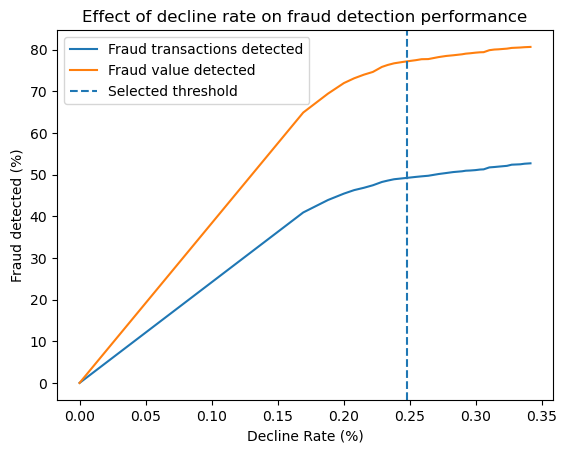

In [25]:
plt.title("Effect of decline rate on fraud detection performance")
plt.plot(DR, TPR, label='Fraud transactions detected')
plt.plot(DR, VPR, label='Fraud value detected')
plt.xlabel("Decline Rate (%)")
plt.ylabel("Fraud detected (%)")
plt.axvline(x=0.248, linestyle='--', label="Selected threshold")
plt.legend()
plt.show()

In [17]:
for i in range(len(VPR)):
    print(threshold[i],DR[i],VPR[i],TPR[i])

0.97 0.34135957201391354 80.67735353537272 52.72727272727272
0.971 0.3368608955245367 80.6121109753872 52.634032634032636
0.972 0.3336218484521854 80.5373230544341 52.494172494172496
0.973 0.32714375430748277 80.43896556372836 52.4009324009324
0.974 0.32354481311598127 80.2644621561482 52.121212121212125
0.975 0.31706671897127864 80.1009414876692 51.934731934731936
0.976 0.31400761895850243 80.05044404974544 51.84149184149184
0.977 0.3102287307074259 79.89268255538074 51.74825174825175
0.978 0.30591000127762413 79.41582273433691 51.28205128205128
0.979 0.30321079538399803 79.39023426058364 51.235431235431236
0.98 0.2996118541924966 79.29351795672524 51.09557109557109
0.981 0.295653018881845 79.15273224612892 51.002331002331005
0.982 0.29241397180949363 79.0623636003128 50.955710955710956
0.983 0.28953481885629245 78.90790126084862 50.815850815850816
0.984 0.2828767776520148 78.6711535497463 50.62937062937063
0.985 0.2774783658647626 78.5052671728609 50.396270396270396
0.986 0.271900007